# ĐỒ ÁN XỬ LÝ NGÔN NGỮ TỰ NHIÊN (NLP)
## Đề tài: Phân loại đa lớp Ngôn từ thù ghét trên Mạng xã hội tiếng Việt (ViHSD)
**Nghiên cứu tham khảo**: *A Large-Scale Dataset for Hate Speech Detection on Vietnamese Social Media Texts* (Luu et al., 2021)

### Mục tiêu Notebook:
1. Tải và xử lý dữ liệu chuẩn **ViHSD** trực tiếp từ GitHub chính thức của tác giả (không cần token Hugging Face).
2. Tiền xử lý & tách từ tiếng Việt bằng thư viện **`pyvi`**.
3. Xây dựng **Baseline máy học truyền thống** (TF-IDF 5k-10k features + Logistic Regression & LinearSVC) - siêu nhanh trên CPU (< 2 phút).
4. Đánh giá đa chiều: **Macro F1 (MF1)**, **Weighted F1 (WF1)**, **Per-class F1** & **Confusion Matrix**.
5. Xuất file **`predictions.csv`** gồm 4 cột: `id`, `text`, `ground_truth`, `predicted_label`.
6. Huấn luyện mô hình Transformer SOTA **PhoBERT-base-v2** trên GPU T4 để đối sánh toàn diện về hiệu năng và thời gian huấn luyện.

### 1. Cài đặt các thư viện cần thiết

In [2]:
!pip install -q pyvi datasets transformers accelerate scikit-learn seaborn matplotlib pandas numpy

### 2. Khai báo thư viện & Kiểm tra phần cứng (CPU/GPU)

In [3]:
import os
import time
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from pyvi import ViTokenizer
from datasets import Dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score
)

# Thiết lập giao diện đồ thị
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 5)

# Kiểm tra thiết bị
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[+] Đang chạy trên thiết bị: {device.upper()}")
if device == "cuda":
    print(f"[+] Tên GPU: {torch.cuda.get_device_name(0)}")

[+] Đang chạy trên thiết bị: CUDA
[+] Tên GPU: Tesla T4


### 3. Tải bộ dữ liệu ViHSD trực tiếp từ GitHub chính thức
> **Giải thích khắc phục lỗi Gated Dataset**:
> Trên Hugging Face, bộ dữ liệu `uitnlp/vihsd` là **Gated Dataset** (yêu cầu đăng nhập và chấp thuận điều khoản).
> Để code chạy **hoàn toàn tự động, 100% không bị lỗi quyền truy cập**, chúng ta tải trực tiếp kho lưu trữ mở của tác giả nghiên cứu (Luu et al.) trên GitHub.

In [5]:
# Tải và giải nén dữ liệu từ GitHub chính thức của tác giả
print("[*] Đang tải dữ liệu ViHSD từ GitHub của tác giả...")
if not os.path.exists("vihsd_data/vihsd/train.csv"):
    !git clone --depth 1 https://github.com/sonlam1102/vihsd.git
    !unzip -q -o vihsd/data/vihsd.zip -d vihsd_data

# Đọc trực tiếp các file CSV
df_train = pd.read_csv("vihsd_data/vihsd/train.csv")
df_val = pd.read_csv("vihsd_data/vihsd/dev.csv")
df_test = pd.read_csv("vihsd_data/vihsd/test.csv")

# Đồng bộ tên cột
if "free_text" in df_train.columns:
    df_train.rename(columns={"free_text": "text", "label_id": "label"}, inplace=True)
    df_val.rename(columns={"free_text": "text", "label_id": "label"}, inplace=True)
    df_test.rename(columns={"free_text": "text", "label_id": "label"}, inplace=True)

# Loại bỏ dòng bị null văn bản (nếu có)
df_train.dropna(subset=["text"], inplace=True)
df_val.dropna(subset=["text"], inplace=True)
df_test.dropna(subset=["text"], inplace=True)

print(f"- Kích thước tập Train: {len(df_train):,} dòng")
print(f"- Kích thước tập Val  : {len(df_val):,} dòng")
print(f"- Kích thước tập Test : {len(df_test):,} dòng")

LABEL_NAMES = ["0 - CLEAN", "1 - OFFENSIVE", "2 - HATE"]

# Thống kê phân bố nhãn
print("\n[+] Phân bố nhãn trên tập Train:")
print(df_train["label"].value_counts().sort_index())

[*] Đang tải dữ liệu ViHSD từ GitHub của tác giả...
- Kích thước tập Train: 24,046 dòng
- Kích thước tập Val  : 2,672 dòng
- Kích thước tập Test : 6,680 dòng

[+] Phân bố nhãn trên tập Train:
label
0    19885
1     1605
2     2556
Name: count, dtype: int64


### 4. Tiền xử lý văn bản & Tách từ tiếng Việt bằng `pyvi`
- Chuẩn hóa Unicode dựng sẵn (NFC).
- Xóa URL, mention, ký tự lặp thừa.
- Sử dụng `pyvi.ViTokenizer.tokenize` để ghép từ ghép (ví dụ: `ngôn_từ thù_ghét`).

In [6]:
TEENCODE_DICT = {
    "k": "không", "ko": "không", "kh": "không", "kg": "không", "hok": "không",
    "đc": "được", "dc": "được", "dk": "được",
    "vs": "với", "ng": "người", "ngta": "người ta", "mn": "mọi người",
    "bt": "biết", "bit": "biết", "cx": "cũng", "cg": "cũng",
    "mik": "mình", "mk": "mình", "fb": "facebook", "cmt": "bình luận",
    "vl": "vãi", "vcl": "vãi", "dm": "địt mẹ", "đm": "địt mẹ"
}

def clean_and_segment(text: str) -> str:
    if not isinstance(text, str):
        return ""
    # 1. Chuẩn hóa NFC
    text = unicodedata.normalize("NFC", text)
    # 2. Xóa URL & Mention
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    # 3. Rút gọn ký tự lặp > 2 lần (ví dụ: 'quaaaa' -> 'qua')
    text = re.sub(r'([a-zA-ZÀ-ỹ])\1{2,}', r'\1\1', text)
    # 4. Viết thường & chuẩn hóa teencode đơn giản
    text = text.lower()
    words = text.split()
    words = [TEENCODE_DICT.get(w, w) for w in words]
    clean_text = " ".join(words)
    clean_text = re.sub(r"\s+", " ", clean_text).strip()
    # 5. Tách từ tiếng Việt bằng pyvi
    segmented_text = ViTokenizer.tokenize(clean_text)
    return segmented_text

print("[*] Đang thực hiện tiền xử lý & tách từ bằng pyvi...")
start_time = time.time()
df_train["processed_text"] = df_train["text"].apply(clean_and_segment)
df_val["processed_text"] = df_val["text"].apply(clean_and_segment)
df_test["processed_text"] = df_test["text"].apply(clean_and_segment)
print(f"[✓] Tiền xử lý hoàn tất trong: {time.time() - start_time:.2f} giây")

# Xem thử 3 mẫu sau xử lý
display(df_train[["text", "processed_text", "label"]].head(3))

[*] Đang thực hiện tiền xử lý & tách từ bằng pyvi...
[✓] Tiền xử lý hoàn tất trong: 7.20 giây


,text,processed_text,label
0,Em được làm fan cứng luôn rồi nè ❤️ reaction q...,em được làm fan cứng luôn rồi nè ❤ ️ reaction ...,0
1,Đúng là bọn mắt híp lò xo thụt :))) bên việt n...,đúng là bọn mắt híp lò_xo thụt : ) ) ) bên việ...,2
2,Đậu Văn Cường giờ giống thằng sida hơn à,đậu văn cường giờ giống thằng sida hơn à,0


### 5. Trích xuất đặc trưng TF-IDF (TF-IDF Vectorization)
- Cấu hình `max_features = 8000` (nằm trong khoảng yêu cầu 5,000 - 10,000 từ).
- Sử dụng `ngram_range = (1, 2)` để bắt cả từ đơn và từ ghép 2 tiếng.

In [8]:
MAX_FEATURES = 8000

print(f"[*] Đang trích xuất đặc trưng TF-IDF (max_features={MAX_FEATURES})...")
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=MAX_FEATURES,
    sublinear_tf=True
)

X_train = tfidf_vectorizer.fit_transform(df_train["processed_text"])
X_val = tfidf_vectorizer.transform(df_val["processed_text"])
X_test = tfidf_vectorizer.transform(df_test["processed_text"])

y_train = df_train["label"].values
y_val = df_val["label"].values
y_test = df_test["label"].values

print(f"[✓] Kích thước ma trận X_train: {X_train.shape}")
print(f"[✓] Kích thước ma trận X_test : {X_test.shape}")

[*] Đang trích xuất đặc trưng TF-IDF (max_features=8000)...
[✓] Kích thước ma trận X_train: (24046, 8000)
[✓] Kích thước ma trận X_test : (6680, 8000)


### 6. Huấn luyện Baseline Machine Learning: Logistic Regression & LinearSVC
- Chạy nhanh trên CPU (< 1 phút).
- Sử dụng tham số `class_weight='balanced'` để xử lý hiện tượng mất cân bằng mẫu.

In [9]:
# 1. Logistic Regression Baseline
print("[*] Đang huấn luyện Logistic Regression...")
t0 = time.time()
lr_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
lr_model.fit(X_train, y_train)
lr_train_time = time.time() - t0
print(f"[✓] Logistic Regression huấn luyện xong trong: {lr_train_time:.2f} giây")

# 2. Linear Support Vector Machine (LinearSVC) Baseline
print("[*] Đang huấn luyện LinearSVC...")
t0 = time.time()
svm_model = LinearSVC(C=1.0, class_weight="balanced", random_state=42, max_iter=2000)
svm_model.fit(X_train, y_train)
svm_train_time = time.time() - t0
print(f"[✓] LinearSVC huấn luyện xong trong: {svm_train_time:.2f} giây")

[*] Đang huấn luyện Logistic Regression...
[✓] Logistic Regression huấn luyện xong trong: 3.25 giây
[*] Đang huấn luyện LinearSVC...
[✓] LinearSVC huấn luyện xong trong: 0.47 giây


### 7. Đánh giá chi tiết Baseline: Macro F1, Weighted F1, Per-class F1 & Confusion Matrix

In [11]:
def evaluate_predictions(y_true, y_pred, model_name="Model"):
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    per_class_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
    acc = accuracy_score(y_true, y_pred)

    print(f"\n{'='*25} {model_name.upper()} {'='*25}")
    print(f"Accuracy         : {acc*100:.2f}%")
    print(f"Macro F1 (MF1)   : {macro_f1:.4f}  <-- Độ đo chính")
    print(f"Weighted F1 (WF1): {weighted_f1:.4f}")
    print("-" * 60)
    print(f"F1 - CLEAN (0)   : {per_class_f1[0]:.4f}")
    print(f"F1 - OFFENSIVE(1): {per_class_f1[1]:.4f}")
    print(f"F1 - HATE (2)    : {per_class_f1[2]:.4f}")
    print("-" * 60)
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, digits=4, zero_division=0))

    return {
        "Model": model_name,
        "Accuracy": acc,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1,
        "F1_CLEAN": per_class_f1[0],
        "F1_OFFENSIVE": per_class_f1[1],
        "F1_HATE": per_class_f1[2]
    }

# Dự đoán trên tập Test
y_pred_lr = lr_model.predict(X_test)
y_pred_svm = svm_model.predict(X_test)

metrics_lr = evaluate_predictions(y_test, y_pred_lr, "TF-IDF + Logistic Regression")
metrics_svm = evaluate_predictions(y_test, y_pred_svm, "TF-IDF + LinearSVC (Baseline)")


========================= TF-IDF + LOGISTIC REGRESSION =========================
Accuracy         : 80.72%
Macro F1 (MF1)   : 0.6060  <-- Độ đo chính
Weighted F1 (WF1): 0.8265
------------------------------------------------------------
F1 - CLEAN (0)   : 0.8977
F1 - OFFENSIVE(1): 0.3784
F1 - HATE (2)    : 0.5419
------------------------------------------------------------

Classification Report:
               precision    recall  f1-score   support

    0 - CLEAN     0.9519    0.8493    0.8977      5548
1 - OFFENSIVE     0.3052    0.4977    0.3784       444
     2 - HATE     0.4563    0.6672    0.5419       688

     accuracy                         0.8072      6680
    macro avg     0.5711    0.6714    0.6060      6680
 weighted avg     0.8579    0.8072    0.8265      6680


========================= TF-IDF + LINEARSVC (BASELINE) =========================
Accuracy         : 85.09%
Macro F1 (MF1)   : 0.6217  <-- Độ đo chính
Weighted F1 (WF1): 0.8512
---------------------------------

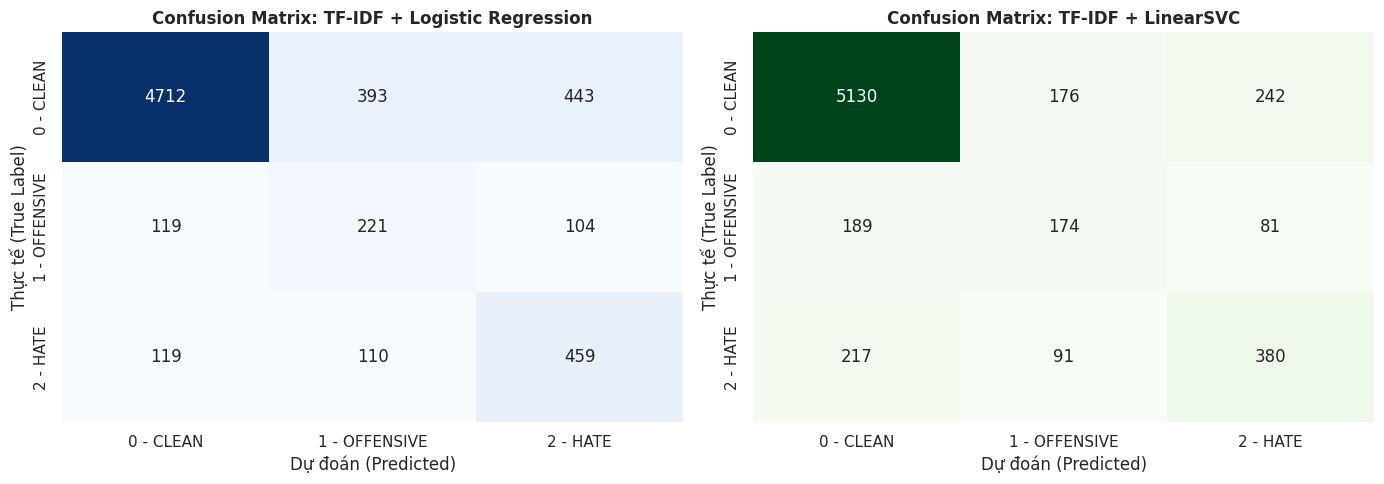

In [12]:
# Vẽ Ma trận nhầm lẫn (Confusion Matrix)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
axes[0].set_title("Confusion Matrix: TF-IDF + Logistic Regression", fontweight="bold")
axes[0].set_xlabel("Dự đoán (Predicted)")
axes[0].set_ylabel("Thực tế (True Label)")

cm_svm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[1],
            xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
axes[1].set_title("Confusion Matrix: TF-IDF + LinearSVC", fontweight="bold")
axes[1].set_xlabel("Dự đoán (Predicted)")
axes[1].set_ylabel("Thực tế (True Label)")

plt.tight_layout()
plt.show()

### 8. Xuất file kết quả dự đoán `predictions.csv`
Cấu trúc đúng theo yêu cầu của giảng viên:
- `id`: Định danh mẫu kiểm thử
- `text`: Nội dung bình luận gốc
- `ground_truth`: Nhãn thực tế
- `predicted_label`: Nhãn mô hình dự đoán (LinearSVC Baseline)

In [13]:
# Chuẩn bị DataFrame xuất file
test_ids = list(range(len(df_test)))

df_predictions = pd.DataFrame({
    "id": test_ids,
    "text": df_test["text"].values,
    "ground_truth": y_test,
    "predicted_label": y_pred_svm
})

output_filename = "predictions.csv"
df_predictions.to_csv(output_filename, index=False, encoding="utf-8-sig")
print(f"[✓] Đã xuất thành công {len(df_predictions)} mẫu vào file '{output_filename}'!")

# Hiển thị 5 dòng đầu tiên của file predictions.csv
display(df_predictions.head(5))

# Nếu chạy trên Google Colab, bạn có thể tải file về máy bằng lệnh dưới:
# from google.colab import files
# files.download('predictions.csv')

[✓] Đã xuất thành công 6680 mẫu vào file 'predictions.csv'!


,id,text,ground_truth,predicted_label
0,0,Đừng cố biện minh =)))) choi lon,0,1
1,1,Haizz. Nthe này thì dân khổ quá,1,1
2,2,the nay ma chi phat gay roi trat tu cong cong ...,0,2
3,3,Mua cho em hộp bcs mĩ sài cho oai :)),0,0
4,4,coin card :3,1,0


### 9. Huấn luyện mô hình Deep Learning PhoBERT-base-v2 (Đối sánh chi tiết)
- Mô hình: `vinai/phobert-base-v2` từ Hugging Face Transformers.
- Fine-tune trên GPU T4 với Sequence Classification (3 classes).
- Đánh giá trên tập test để so sánh trực diện với Baseline TF-IDF.

In [14]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)

MODEL_NAME = "vinai/phobert-base-v2"
print(f"[*] Đang khởi tạo Tokenizer từ: {MODEL_NAME}")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=False)

def tokenize_fn(examples):
    # PhoBERT được huấn luyện với đầu vào đã tách từ bằng dấu gạch dưới
    return tokenizer(examples["processed_text"], truncation=True, max_length=128)

# Chuẩn bị Hugging Face Dataset từ Pandas
hf_train = Dataset.from_pandas(df_train[["processed_text", "label"]])
hf_val = Dataset.from_pandas(df_val[["processed_text", "label"]])
hf_test = Dataset.from_pandas(df_test[["processed_text", "label"]])

tokenized_train = hf_train.map(tokenize_fn, batched=True)
tokenized_val = hf_val.map(tokenize_fn, batched=True)
tokenized_test = hf_test.map(tokenize_fn, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def compute_metrics_hf(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    macro_f1 = f1_score(labels, preds, average="macro", zero_division=0)
    weighted_f1 = f1_score(labels, preds, average="weighted", zero_division=0)
    acc = accuracy_score(labels, preds)
    return {
        "accuracy": acc,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1
    }

print("[✓] Chuẩn bị dữ liệu cho PhoBERT hoàn tất!")

[*] Đang khởi tạo Tokenizer từ: vinai/phobert-base-v2


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

Map:   0%|          | 0/24046 [00:00<?, ? examples/s]

Map:   0%|          | 0/2672 [00:00<?, ? examples/s]

Map:   0%|          | 0/6680 [00:00<?, ? examples/s]

[✓] Chuẩn bị dữ liệu cho PhoBERT hoàn tất!


In [15]:
# Khởi tạo mô hình PhoBERT-base-v2
import inspect
print("[*] Đang tải pre-trained weights cho PhoBERT...")
model_phobert = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3)

# Tương thích linh hoạt với mọi phiên bản Transformers
args_params = inspect.signature(TrainingArguments.__init__).parameters
eval_arg_name = "eval_strategy" if "eval_strategy" in args_params else "evaluation_strategy"

training_args = TrainingArguments(
    output_dir="./phobert_vihsd_output",
    **{eval_arg_name: "epoch"},
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=(device == "cuda"),
    logging_steps=100,
    report_to="none"
)

# Khắc phục lỗi: Transformers phiên bản mới đổi 'tokenizer' thành 'processing_class'
trainer_params = inspect.signature(Trainer.__init__).parameters
trainer_kwargs = {
    "model": model_phobert,
    "args": training_args,
    "train_dataset": tokenized_train,
    "eval_dataset": tokenized_val,
    "data_collator": data_collator,
    "compute_metrics": compute_metrics_hf
}

if "processing_class" in trainer_params:
    trainer_kwargs["processing_class"] = tokenizer
elif "tokenizer" in trainer_params:
    trainer_kwargs["tokenizer"] = tokenizer

trainer = Trainer(**trainer_kwargs)

print("[*] Bắt đầu Fine-tuning PhoBERT...")
t_phobert_start = time.time()
trainer.train()
phobert_train_time = time.time() - t_phobert_start
print(f"[✓] Huấn luyện PhoBERT hoàn tất trong: {phobert_train_time/60:.2f} phút")

[*] Đang tải pre-trained weights cho PhoBERT...


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base-v2
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[*] Bắt đầu Fine-tuning PhoBERT...


... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[✓] Huấn luyện PhoBERT hoàn tất trong: 6.41 phút


In [12]:
# Dự đoán tập Test với PhoBERT
print("[*] Đang dự đoán trên tập Test với PhoBERT...")
test_predictions = trainer.predict(tokenized_test)
y_pred_phobert = np.argmax(test_predictions.predictions, axis=-1)

metrics_phobert = evaluate_predictions(y_test, y_pred_phobert, "PhoBERT-base-v2 Fine-tuned")

# Xuất thêm predictions của PhoBERT để đối sánh
df_pred_phobert = pd.DataFrame({
    "id": test_ids,
    "text": df_test["text"].values,
    "ground_truth": y_test,
    "predicted_label": y_pred_phobert
})
df_pred_phobert.to_csv("predictions_phobert.csv", index=False, encoding="utf-8-sig")
print("[✓] Đã lưu file 'predictions_phobert.csv'!")

[*] Đang dự đoán trên tập Test với PhoBERT...



========================= PHOBERT-BASE-V2 FINE-TUNED =========================
Accuracy         : 88.28%
Macro F1 (MF1)   : 0.6820  <-- Độ đo chính
Weighted F1 (WF1): 0.8800
------------------------------------------------------------
F1 - CLEAN (0)   : 0.9439
F1 - OFFENSIVE(1): 0.4784
F1 - HATE (2)    : 0.6237
------------------------------------------------------------

Classification Report:
               precision    recall  f1-score   support

    0 - CLEAN     0.9345    0.9535    0.9439      5548
1 - OFFENSIVE     0.4839    0.4730    0.4784       444
     2 - HATE     0.6786    0.5770    0.6237       688

     accuracy                         0.8828      6680
    macro avg     0.6990    0.6678    0.6820      6680
 weighted avg     0.8782    0.8828    0.8800      6680

[✓] Đã lưu file 'predictions_phobert.csv'!


### 10. Bảng tổng kết và Biểu đồ đối sánh hiệu năng & thời gian huấn luyện


================ BẢNG ĐỐI SÁNH HIỆU NĂNG VÀ THỜI GIAN ================


,Mô hình,Phần cứng,Thời gian Train (s),Accuracy,Macro F1,Weighted F1,F1 HATE
0,TF-IDF + Logistic Regression,CPU,2.28,80.72%,0.6060,0.8265,0.5419
1,TF-IDF + LinearSVC (Baseline),CPU,0.55,85.09%,0.6217,0.8512,0.5464
2,PhoBERT-base-v2 (Fine-tuned),GPU T4,430.75,88.28%,0.6820,0.8800,0.6237


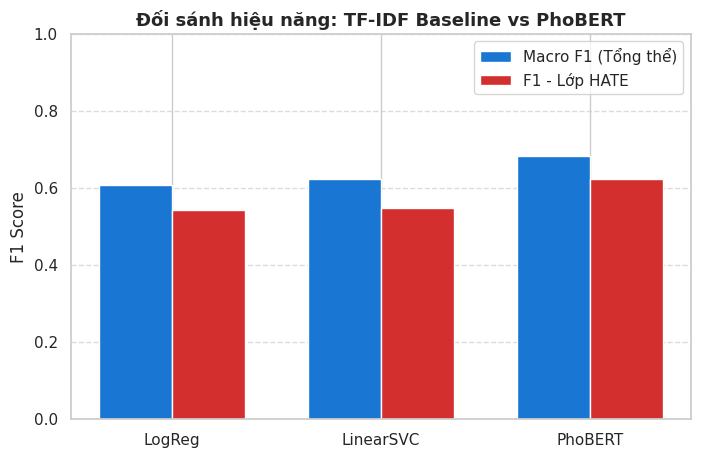

In [13]:
# Tổng hợp bảng so sánh
comparison_df = pd.DataFrame([
    {
        "Mô hình": "TF-IDF + Logistic Regression",
        "Phần cứng": "CPU",
        "Thời gian Train (s)": round(lr_train_time, 2),
        "Accuracy": f"{metrics_lr['Accuracy']*100:.2f}%",
        "Macro F1": round(metrics_lr['Macro_F1'], 4),
        "Weighted F1": round(metrics_lr['Weighted_F1'], 4),
        "F1 HATE": round(metrics_lr['F1_HATE'], 4)
    },
    {
        "Mô hình": "TF-IDF + LinearSVC (Baseline)",
        "Phần cứng": "CPU",
        "Thời gian Train (s)": round(svm_train_time, 2),
        "Accuracy": f"{metrics_svm['Accuracy']*100:.2f}%",
        "Macro F1": round(metrics_svm['Macro_F1'], 4),
        "Weighted F1": round(metrics_svm['Weighted_F1'], 4),
        "F1 HATE": round(metrics_svm['F1_HATE'], 4)
    },
    {
        "Mô hình": "PhoBERT-base-v2 (Fine-tuned)",
        "Phần cứng": "GPU T4",
        "Thời gian Train (s)": round(phobert_train_time, 2),
        "Accuracy": f"{metrics_phobert['Accuracy']*100:.2f}%",
        "Macro F1": round(metrics_phobert['Macro_F1'], 4),
        "Weighted F1": round(metrics_phobert['Weighted_F1'], 4),
        "F1 HATE": round(metrics_phobert['F1_HATE'], 4)
    }
])

print("\n================ BẢNG ĐỐI SÁNH HIỆU NĂNG VÀ THỜI GIAN ================")
display(comparison_df)

# Trực quan hóa so sánh Macro F1 và F1 HATE
models = ["LogReg", "LinearSVC", "PhoBERT"]
macro_f1s = [metrics_lr['Macro_F1'], metrics_svm['Macro_F1'], metrics_phobert['Macro_F1']]
hate_f1s = [metrics_lr['F1_HATE'], metrics_svm['F1_HATE'], metrics_phobert['F1_HATE']]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, macro_f1s, width, label='Macro F1 (Tổng thể)', color='#1976D2')
plt.bar(x + width/2, hate_f1s, width, label='F1 - Lớp HATE', color='#D32F2F')

plt.ylabel('F1 Score')
plt.title('Đối sánh hiệu năng: TF-IDF Baseline vs PhoBERT', fontsize=13, fontweight='bold')
plt.xticks(x, models)
plt.ylim(0, 1.0)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 11. Hướng dẫn huấn luyện tiếp tục trên bộ dữ liệu riêng của nhóm
Khi nhóm hoàn tất thu thập & gán nhãn tập dữ liệu riêng (chuẩn bị file CSV gồm 2 cột: `text` và `label` với 3 giá trị `0, 1, 2`):
```python
# Nạp dataset của nhóm:
# df_custom = pd.read_csv('your_group_dataset.csv')
# df_custom['processed_text'] = df_custom['text'].apply(clean_and_segment)
# X_custom = tfidf_vectorizer.transform(df_custom['processed_text'])
# preds_custom = svm_model.predict(X_custom)
```